# 7장 3차시 실습

Iris 모델 비교, 과적합, 교차검증, 특징 공학, 정밀도·재현율, PCA, CO2 시계열을 순서대로 실행합니다.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

iris = load_iris(as_frame=True)
X = iris.frame[iris.feature_names]
y = iris.target_names[iris.target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)

## 1. 모델은 하나가 아니다

In [2]:
import sklearn
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "decision tree (depth 2)": DecisionTreeClassifier(max_depth=2, random_state=0),
    "logistic regression":      LogisticRegression(max_iter=1000),
    "kNN (k=5)":       KNeighborsClassifier(n_neighbors=5),
    "random forest":      RandomForestClassifier(n_estimators=100, random_state=0),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name:24s} training {m.score(X_train, y_train):.3f}  test {m.score(X_test, y_test):.3f}")

decision tree (depth 2)  training 0.958  test 0.967
logistic regression      training 0.967  test 1.000
kNN (k=5)                training 0.950  test 0.967
random forest            training 1.000  test 1.000


### 같은 꽃의 모델별 예측과 모델 저장

In [4]:
new = pd.DataFrame([[6.1, 2.6, 5.6, 1.4]], columns=iris.feature_names)
for name, m in models.items():
    print(f"{name:24s} {m.predict(new)[0]:12s} {m.predict_proba(new).round(2)}")

import joblib

rf = models["random forest"]
joblib.dump(rf, "iris_model_rf.pkl")

decision tree (depth 2)  versicolor   [[0.  0.9 0.1]]
logistic regression      virginica    [[0.   0.19 0.81]]
kNN (k=5)                virginica    [[0.  0.2 0.8]]
random forest            virginica    [[0.   0.48 0.52]]


['iris_model_rf.pkl']

## 2. 과적합 : 깊이를 늘리면 (반품 데이터)

In [5]:
sales = pd.read_csv("sales_clean.csv")
d = sales.dropna(subset=["customer_age", "satisfaction"])
Xr = d[["quantity", "unit_price", "customer_age", "satisfaction"]]
yr = (d["status"] == "반품").astype(int)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=0)
print("return rate :", round(yr.mean() * 100, 1), "%   baseline (모두 아니오) test accuracy :", round((yr_test == 0).mean(), 3))

return rate : 8.0 %   baseline (모두 아니오) test accuracy : 0.892


In [6]:
rows = []
for dep in [1, 2, 3, 5, 8, None]:
    m = DecisionTreeClassifier(max_depth=dep, random_state=0).fit(Xr_train, yr_train)
    rows.append([str(dep), m.get_n_leaves(),
                 round(m.score(Xr_train, yr_train), 3), round(m.score(Xr_test, yr_test), 3)])
tbl = pd.DataFrame(rows, columns=["max_depth", "leaves", "training", "test"])
tbl

,max_depth,leaves,training,test
0,1,2,0.927,0.892
1,2,4,0.928,0.892
2,3,7,0.931,0.870
3,5,16,0.938,0.865
4,8,37,0.953,0.854
5,None,98,1.000,0.811


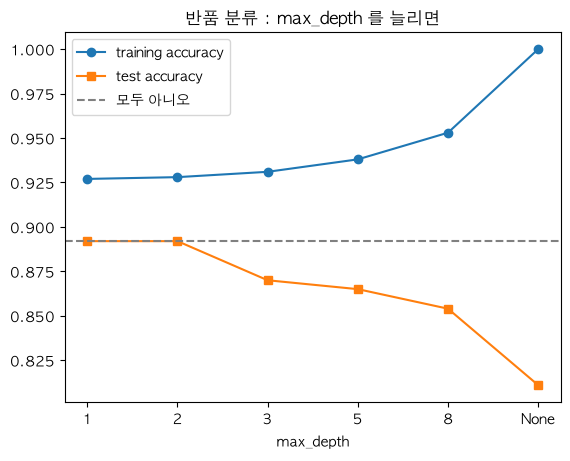

In [7]:
plt.plot(range(6), tbl["training"], "o-", label="training accuracy")
plt.plot(range(6), tbl["test"], "s-", label="test accuracy")
plt.axhline((yr_test == 0).mean(), color="gray", ls="--", label="모두 아니오")
plt.xticks(range(6), tbl["max_depth"])
plt.xlabel("max_depth")
plt.title("반품 분류 : max_depth 를 늘리면")
plt.legend()
plt.show()

## 3. 교차검증 : 나눔 한 번을 믿지 않는다

In [8]:
from sklearn.model_selection import cross_val_score

m = DecisionTreeClassifier(max_depth=2, random_state=0)
scores = cross_val_score(m, X, y, cv=5)
print(scores.round(3))
print("mean :", scores.mean().round(3), " std :", scores.std().round(3))

[0.933 0.967 0.9   0.867 1.   ]
mean : 0.933  std : 0.047


## 4. 특징 만들기 : 선형 회귀는 곱셈을 모른다

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

Xs = sales[["quantity", "unit_price"]]
ys = sales["total_sales"]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.2, random_state=0)

lin = LinearRegression().fit(Xs_train, ys_train)
print("linear (quantity, unit_price)     test R² :", round(lin.score(Xs_test, ys_test), 3))

Xs2_train = Xs_train.assign(qp=Xs_train["quantity"] * Xs_train["unit_price"])
Xs2_test  = Xs_test.assign(qp=Xs_test["quantity"] * Xs_test["unit_price"])
lin2 = LinearRegression().fit(Xs2_train, ys_train)
print("linear (quantity, unit_price, qp) test R² :", round(lin2.score(Xs2_test, ys_test), 3))
print("coef :", lin2.coef_.round(3), " intercept :", round(lin2.intercept_, 1))

linear (quantity, unit_price)     test R² : 0.862
linear (quantity, unit_price, qp) test R² : 1.0
coef : [0. 0. 1.]  intercept : -0.0


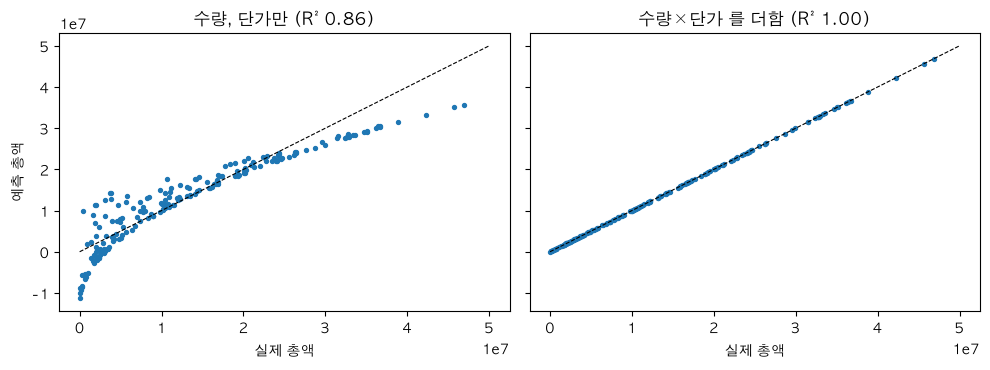

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
ax[0].scatter(ys_test, lin.predict(Xs_test), s=8)
ax[0].set_title("수량, 단가만 (R² 0.86)")
ax[1].scatter(ys_test, lin2.predict(Xs2_test), s=8)
ax[1].set_title("수량×단가 를 더함 (R² 1.00)")
for a in ax:
    a.plot([0, 5e7], [0, 5e7], "k--", lw=0.8)
    a.set_xlabel("실제 총액")
ax[0].set_ylabel("예측 총액")
plt.tight_layout()
plt.show()

In [11]:
pd.get_dummies(sales[["quantity", "category"]], dtype=int).head(3)

,quantity,category_가구,category_도서,category_식품,category_의류,category_전자제품
0,61,0,0,0,0,1
1,64,0,0,1,0,0
2,5,0,0,0,1,0
